# Animal Shelter Analytics v2 — 문제점 개선판

기존 `Animal_Shelter_Analytics_Final.ipynb`를 기준으로, 분석 보고서(`Animal_Shelter_프로젝트_분석보고서.pdf`) 7장에서 지적한 **문제 7개를 모두 반영**한 노트북입니다.

| 문제 | 내용 | 이 노트북의 해결 방법 | 섹션 |
|---|---|---|---|
| 1 | 직접모델 vs 2단계 비교 기준이 다름 | **같은 test 전체**에서 최종 점수로 비교 + 동물 ID 기준 교차검증으로 전략 선택 | 10 |
| 2 | 안락사 성능이 야생동물에 좌우됨 | 전체 동물 모델과 **개·고양이 모델** 분리, 야생동물은 규칙 기준선과 비교 | 6, 10 |
| 3 | 방문 순번 병합 오류 | 중복 제거 + **`merge_asof`(입소 이후 첫 퇴소)** 병합, 기존 방식과 비교 | 3 |
| 4 | 이름 변수 누수 가능성 | 이름을 3종(없음 / 보호소 부여 `*` / 원래 이름)으로 구분, **`has_original_name`** 사용, 제외 실험 | 5, 8 |
| 5 | 불균형 실험 검증 방식 | **StratifiedGroupKFold**, 임곗값은 **OOF(검증 폴드) 예측**으로 결정, **SMOTENC** 사용 | 11 |
| 6 | 발표·노트북 불일치, 재현성 | 입양 모델 튜닝·SHAP을 **한 노트북에 통합**, 상대경로, 그림 자동 저장(`figures_v2/`) | 2, 9 |
| 7 | 기타 (분할 전 그룹화, 종 공통 나이 구간, 계절 실험, 시간 검증) | 전처리를 **파이프라인으로 train에서만 학습**, **종별 생애단계**, 계절 제외 실험, **시간 기준 검증** | 5, 7, 8, 12 |

> 실행 방법: 이 노트북을 `반려동물 데이터셋.zip`과 같은 폴더에 두고 위에서부터 차례로 실행합니다. (필요 패키지: pandas, scikit-learn ≥ 1.2, lightgbm, imbalanced-learn, shap)

## 1. 환경 설정

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # Windows에서 joblib 코어 탐지 오류 방지

import zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             recall_score, precision_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report)
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

SEED = 42
FIG_DIR = "figures_v2"
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=120, bbox_inches="tight")

## 2. 데이터 불러오기 — 상대경로 【문제 6】
- 기존 노트북은 개인 PC의 절대경로(`C:\Users\...`)를 사용해 다른 컴퓨터에서 실행할 수 없었습니다.
- 이제 노트북과 같은 폴더의 `반려동물 데이터셋.zip`에서 **압축을 풀지 않고 바로** 읽습니다.

In [2]:
ZIP_PATH = "반려동물 데이터셋.zip"
with zipfile.ZipFile(ZIP_PATH) as z:
    intakes = pd.read_csv(z.open("Austin_Animal_Center_Intakes.csv"))
    outcomes = pd.read_csv(z.open("Austin_Animal_Center_Outcomes.csv"))

for t in (intakes, outcomes):
    t["DateTime"] = pd.to_datetime(t["DateTime"], format="mixed")

print("Intakes :", intakes.shape, intakes["DateTime"].min(), "~", intakes["DateTime"].max())
print("Outcomes:", outcomes.shape, outcomes["DateTime"].min(), "~", outcomes["DateTime"].max())

Intakes : (124120, 12) 2013-10-01 07:51:00 ~ 2021-03-03 17:13:00
Outcomes: (124491, 12) 2013-10-01 09:31:00 ~ 2021-03-03 17:57:00


## 3. 입·퇴소 병합 개선 【문제 3】
**기존 방식**: 같은 동물의 n번째 입소 ↔ n번째 퇴소를 짝지음 (`visit_seq`).
입소·퇴소 횟수가 다르면(수집 시작 전 입소, 기록 누락, 중복) 순번이 밀려 **엉뚱한 퇴소와 연결**됩니다.

**개선 방식**
1. 완전히 같은 중복 행 제거
2. `pd.merge_asof(direction="forward")`: 각 입소에 대해 **입소 시각 이후 가장 가까운 퇴소**를 연결
3. 두 입소가 같은 퇴소에 연결되면(중간 퇴소 기록 누락) **더 최근 입소만** 남김
4. 퇴소 기록이 없는 입소(아직 보호 중)는 제외

In [3]:
dup_in, dup_out = intakes.duplicated().sum(), outcomes.duplicated().sum()
intakes = intakes.drop_duplicates().reset_index(drop=True)
outcomes = outcomes.drop_duplicates().reset_index(drop=True)
print(f"완전 중복 제거: 입소 {dup_in}행, 퇴소 {dup_out}행")

cnt = pd.concat([intakes.groupby("Animal ID").size(), outcomes.groupby("Animal ID").size()], axis=1).fillna(0)
print(f"입소 횟수 != 퇴소 횟수인 동물: {(cnt[0] != cnt[1]).sum():,} / {len(cnt):,}")


def merge_by_visit_seq(i, o):
    # 기존 방식 (비교용)
    i = i.sort_values(["Animal ID", "DateTime"]).copy()
    o = o.sort_values(["Animal ID", "DateTime"]).copy()
    i["visit_seq"] = i.groupby("Animal ID").cumcount()
    o["visit_seq"] = o.groupby("Animal ID").cumcount()
    return i.merge(o, on=["Animal ID", "visit_seq"], suffixes=("_intake", "_outcome"))


def merge_forward(i, o):
    # 개선 방식: 입소 이후 첫 퇴소를 연결
    i = i.rename(columns={"DateTime": "DateTime_intake"}).sort_values("DateTime_intake")
    o = o.rename(columns={"DateTime": "DateTime_outcome"}).sort_values("DateTime_outcome")
    m = pd.merge_asof(i, o, left_on="DateTime_intake", right_on="DateTime_outcome",
                      by="Animal ID", direction="forward", suffixes=("_intake", "_outcome"))
    m = m.dropna(subset=["DateTime_outcome"])
    m = (m.sort_values("DateTime_intake")
           .drop_duplicates(subset=["Animal ID", "DateTime_outcome"], keep="last"))
    return m.reset_index(drop=True)


old = merge_by_visit_seq(intakes, outcomes)
df = merge_forward(intakes, outcomes)

old_los = (old["DateTime_outcome"] - old["DateTime_intake"]).dt.days
new_los = (df["DateTime_outcome"] - df["DateTime_intake"]).dt.days

key = ["Animal ID", "DateTime_intake"]
cmp = old[key + ["DateTime_outcome", "Outcome Type"]].merge(
    df[key + ["DateTime_outcome", "Outcome Type"]], on=key, suffixes=("_old", "_new"))
changed_match = (cmp["DateTime_outcome_old"] != cmp["DateTime_outcome_new"]).sum()
changed_type = (cmp["Outcome Type_old"].fillna("NA") != cmp["Outcome Type_new"].fillna("NA")).sum()

merge_summary = pd.DataFrame({
    "기존 (visit_seq)": [len(old), (old_los < 0).sum(), (old_los > 365).sum()],
    "개선 (merge_asof)": [len(df), (new_los < 0).sum(), (new_los > 365).sum()],
}, index=["병합 행 수", "체류기간 < 0 행", "체류기간 > 365일 행"])
display(merge_summary)
print(f"두 방식 모두에 있는 입소 기록 중 연결된 퇴소가 달라진 기록: {changed_match:,}건 "
      f"(그중 결과 유형이 바뀐 기록: {changed_type:,}건)")

완전 중복 제거: 입소 19행, 퇴소 17행


입소 횟수 != 퇴소 횟수인 동물: 1,489 / 111,740


,기존 (visit_seq),개선 (merge_asof)
병합 행 수,123543,122960
체류기간 < 0 행,694,0
체류기간 > 365일 행,304,307


두 방식 모두에 있는 입소 기록 중 연결된 퇴소가 달라진 기록: 167건 (그중 결과 유형이 바뀐 기록: 58건)


## 4. 타깃 정의
교수님 코멘트 1에 따라 결과를 5개 범주로 정리한 뒤, 운영 목적별 이진 타깃 두 개를 만듭니다.
- `target_adoption`: 입양 = 1
- `target_euthanasia`: 안락사 = 1

In [4]:
df = df[df["Outcome Type"].notna()].copy()
outcome_map = {"Adoption": "입양", "Return to Owner": "반환", "Transfer": "이송", "Euthanasia": "안락사"}
df["outcome_category"] = df["Outcome Type"].map(outcome_map).fillna("기타")
df["target_adoption"] = (df["outcome_category"] == "입양").astype(int)
df["target_euthanasia"] = (df["outcome_category"] == "안락사").astype(int)

print(df["outcome_category"].value_counts(normalize=True).round(3).to_string())

outcome_category
입양     0.445
이송     0.294
반환     0.174
안락사    0.067
기타     0.020


## 5. 전처리 · 특성공학 【문제 4, 7 / 교수님 코멘트 5, 6】
| 변수 | 처리 | 변경 이유 |
|---|---|---|
| 나이 | 문자열 → 일(day). 결측·음수·30세 초과 행 삭제 | 코멘트 4 (기존 유지) |
| **생애단계 `life_stage`** | **종별 구간**: 개 1/3/7세, 고양이 1/6/10세, 기타 1세 기준 | 코멘트 5: 동물마다 나이 스케일이 다름 |
| **이름 `name_type`** | 없음 / 보호소 부여(`*`로 시작) / 원래 이름 | 문제 4: 보호소가 나중에 붙인 이름은 누수 위험 |
| `has_original_name` | 원래 이름이 있을 때만 1 | 입소 시점에 확실히 알 수 있는 정보만 사용 |
| **품종군 `breed_group`** | 품종명 키워드로 불리계·소형·테리어·목양견·사냥견·하운드·워킹 / 고양이 털 길이 | 코멘트 6: 의미 있는 상위 범주 |
| 혼종 `is_mixed_breed` | 'Mix' **또는 '/'(두 품종 혼합)** 포함 | 기존에는 'A/B' 형태의 혼종을 놓침 |
| 다색 `is_multicolor` | 색상에 '/' 포함 | 코멘트 6 (기존 유지) |
| 체류기간 | **EDA에만 사용**, 모델에는 사용하지 않음 | 퇴소 후에야 확정되는 정보 (누수) |

In [5]:
df["animal_type"] = df["Animal Type_intake"].replace({"Bird": "Other", "Livestock": "Other"})


def age_to_days(s):
    if pd.isna(s):
        return np.nan
    parts = str(s).split()
    if len(parts) != 2:
        return np.nan
    try:
        num = int(parts[0])
    except ValueError:
        return np.nan
    unit = parts[1].lower()
    for key, mult in (("year", 365), ("month", 30), ("week", 7), ("day", 1)):
        if key in unit:
            return num * mult
    return np.nan


df["age_days"] = df["Age upon Intake"].apply(age_to_days)
bad_age = df["age_days"].isna() | (df["age_days"] < 0) | (df["age_days"] > 30 * 365)
print(f"나이 결측·오류 삭제: {bad_age.sum()}행")
df = df[~bad_age].copy()

# 날짜 파생
df["intake_year"] = df["DateTime_intake"].dt.year
df["intake_month"] = df["DateTime_intake"].dt.month
season_map = {1: "한겨울", 2: "한겨울", 3: "봄", 4: "봄", 5: "초여름", 6: "초여름",
              7: "한여름", 8: "한여름", 9: "가을", 10: "가을", 11: "초겨울", 12: "초겨울"}
df["intake_season"] = df["intake_month"].map(season_map)
df["length_of_stay_days"] = (df["DateTime_outcome"] - df["DateTime_intake"]).dt.days  # EDA 전용

# 성별 / 중성화
sex_raw = df["Sex upon Intake"].fillna("Unknown")
df["sex"] = sex_raw.map({"Intact Male": "Male", "Neutered Male": "Male",
                         "Intact Female": "Female", "Spayed Female": "Female"}).fillna("Unknown")
df["sterilized_status"] = sex_raw.map({"Intact Male": "Not Sterilized", "Intact Female": "Not Sterilized",
                                       "Neutered Male": "Sterilized", "Spayed Female": "Sterilized"}).fillna("Unknown")

# 이름 3종 구분 【문제 4】
name = df["Name_intake"]
is_star = name.astype(str).str.startswith("*")
df["name_type"] = np.select([name.isna(), is_star], ["없음", "보호소 부여(*)"], "원래 이름")
df["has_name"] = name.notna().astype(int)                          # 기존 변수 (비교용)
df["has_original_name"] = (name.notna() & ~is_star).astype(int)   # 개선 변수

# 품종 · 색상
breed = df["Breed_intake"].fillna("Unknown")
df["is_mixed_breed"] = breed.str.contains(r"Mix|/", case=False).astype(int)
df["is_multicolor"] = df["Color_intake"].fillna("").str.contains("/").astype(int)

DOG_GROUPS = [
    ("불리계", ["pit bull", "staffordshire", "american bulldog", "bull terrier", "boxer"]),
    ("소형·토이", ["chihuahua", "yorkshire", "maltese", "shih tzu", "pomeranian", "pug", "miniature", "toy",
                "papillon", "pekingese", "lhasa", "bichon", "cavalier", "havanese", "jack russell", "rat terrier"]),
    ("테리어", ["terrier", "schnauzer"]),
    ("목양견", ["shepherd", "collie", "heeler", "cattle dog", "corgi", "sheepdog", "catahoula"]),
    ("사냥·리트리버", ["retriever", "labrador", "spaniel", "pointer", "setter", "vizsla", "weimaraner"]),
    ("하운드", ["hound", "beagle", "dachshund", "basset", "greyhound", "whippet", "plott"]),
    ("워킹", ["husky", "malamute", "rottweiler", "great dane", "mastiff", "doberman", "pyrenees", "akita",
            "anatolian", "cane corso", "bernard", "bernese"]),
    ("논스포팅", ["poodle", "chow", "dalmatian", "shiba", "bulldog"]),
]


def breed_group(animal_type, breed_str):
    first = breed_str.lower().split("/")[0]
    if animal_type == "Dog":
        for group, keys in DOG_GROUPS:
            if any(k in first for k in keys):
                return group
        return "기타견"
    if animal_type == "Cat":
        if "shorthair" in first:
            return "고양이-단모"
        if "medium hair" in first:
            return "고양이-중모"
        if "longhair" in first:
            return "고양이-장모"
        return "고양이-품종묘"
    return "기타동물"


df["breed_group"] = [breed_group(a, b) for a, b in zip(df["animal_type"], breed)]

# 종별 생애단계 【코멘트 5】
age_y = df["age_days"] / 365
df["life_stage"] = "성체"
stage_rules = {
    "Dog": ([0, 1, 3, 7, np.inf], ["새끼", "어린 성체", "성체", "노령"]),
    "Cat": ([0, 1, 6, 10, np.inf], ["새끼", "어린 성체", "성체", "노령"]),
    "Other": ([0, 1, np.inf], ["새끼", "성체"]),
}
for t, (bins, labels) in stage_rules.items():
    m = df["animal_type"] == t
    df.loc[m, "life_stage"] = pd.cut(age_y[m], bins=bins, labels=labels, right=False).astype(str)

print("최종 분석 데이터:", df.shape)
display(pd.crosstab(df["breed_group"], df["animal_type"]).loc[lambda x: x.sum(axis=1) > 0])

나이 결측·오류 삭제: 7행


최종 분석 데이터: (122935, 41)


animal_type,Cat,Dog,Other
breed_group,,,
고양이-단모,37885,0,0
고양이-장모,1807,0,0
고양이-중모,3872,0,0
고양이-품종묘,2402,0,0
기타견,0,3180,0
기타동물,0,0,7142
논스포팅,0,830,0
목양견,0,11878,0
불리계,0,14053,0


## 6. EDA — 안락사의 구성과 이름 변수 점검 【문제 2, 4】

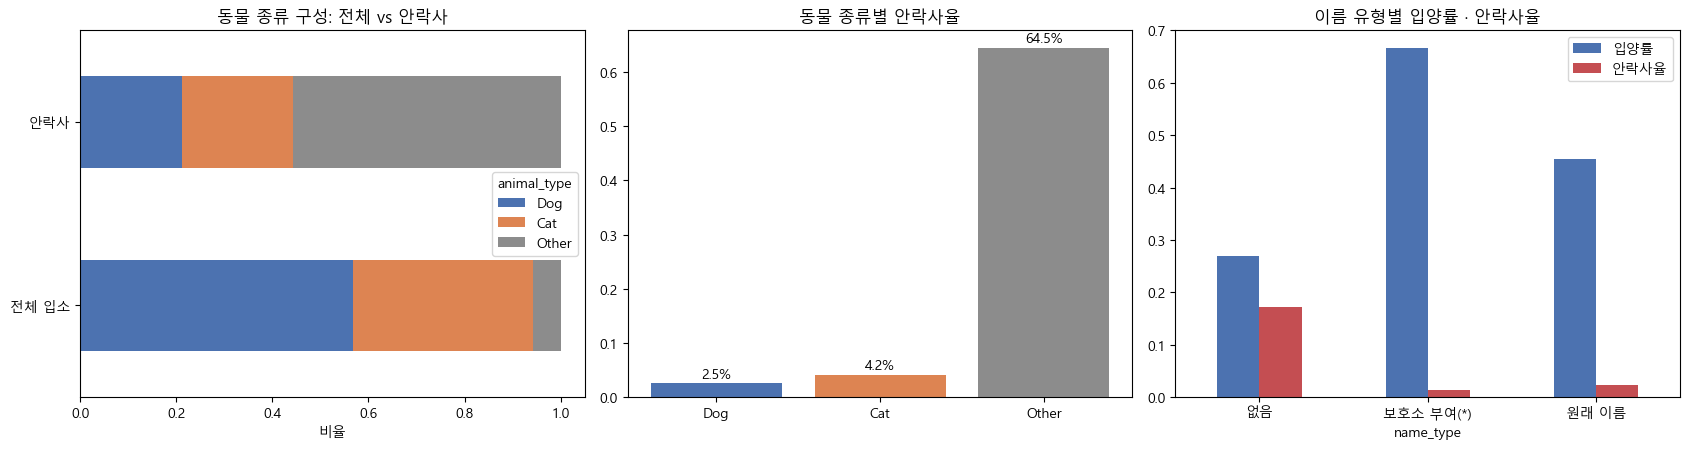

[안락사 중 동물 종류 비율]
animal_type
Other    0.557
Cat      0.231
Dog      0.212

[안락사 중 입소 유형 비율]
Intake Type
Wildlife              0.515
Stray                 0.326
Owner Surrender       0.089
Public Assist         0.046
Euthanasia Request    0.024

[동물 종류별 안락사 사유 상위 3개]  (Outcome Subtype은 EDA에만 사용)
  Other: Rabies Risk 79%, Suffering 16%, Medical 4%
  Dog  : Suffering 48%, Aggressive 30%, Behavior 9%
  Cat  : Suffering 87%, At Vet 5%, Rabies Risk 4%

[이름 유형별 규모와 결과]


,건수,입양률,안락사율
name_type,,,
보호소 부여(*),27831,0.667,0.013
없음,38509,0.270,0.172
원래 이름,56595,0.455,0.022


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

euth = df[df["target_euthanasia"] == 1]
share = pd.DataFrame({"전체 입소": df["animal_type"].value_counts(normalize=True),
                      "안락사": euth["animal_type"].value_counts(normalize=True)}).reindex(["Dog", "Cat", "Other"])
share.T.plot(kind="barh", stacked=True, ax=axes[0], color=["#4C72B0", "#DD8452", "#8C8C8C"])
axes[0].set_title("동물 종류 구성: 전체 vs 안락사")
axes[0].set_xlabel("비율")

rate = df.groupby("animal_type")["target_euthanasia"].mean().reindex(["Dog", "Cat", "Other"])
axes[1].bar(rate.index, rate.values, color=["#4C72B0", "#DD8452", "#8C8C8C"])
for i, v in enumerate(rate.values):
    axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center")
axes[1].set_title("동물 종류별 안락사율")

nm = df.groupby("name_type")[["target_adoption", "target_euthanasia"]].mean().reindex(["없음", "보호소 부여(*)", "원래 이름"])
nm.plot(kind="bar", ax=axes[2], color=["#4C72B0", "#C44E52"], rot=0)
axes[2].set_title("이름 유형별 입양률 · 안락사율")
axes[2].legend(["입양률", "안락사율"])
plt.tight_layout()
savefig("01_euthanasia_composition_and_name.png")
plt.show()

print("[안락사 중 동물 종류 비율]")
print(euth["animal_type"].value_counts(normalize=True).round(3).to_string())
print("\n[안락사 중 입소 유형 비율]")
print(euth["Intake Type"].value_counts(normalize=True).round(3).head(5).to_string())
print("\n[동물 종류별 안락사 사유 상위 3개]  (Outcome Subtype은 EDA에만 사용)")
for t in ["Other", "Dog", "Cat"]:
    s = euth.loc[euth["animal_type"] == t, "Outcome Subtype"].value_counts(normalize=True).head(3).round(3)
    print(f"  {t:5s}:", ", ".join(f"{k} {v:.0%}" for k, v in s.items()))
print("\n[이름 유형별 규모와 결과]")
display(df.groupby("name_type").agg(건수=("target_adoption", "size"),
                                    입양률=("target_adoption", "mean"),
                                    안락사율=("target_euthanasia", "mean")).round(3))

**해석**
- 야생동물을 포함한 `Other`는 전체 입소의 약 6%지만 **안락사의 절반 이상**을 차지하고, 사유는 대부분 광견병 위험입니다. 이런 안락사는 보호소가 개입해서 바꿀 수 있는 결과가 아닙니다.
  → 모델링의 주 대상을 **개·고양이**로 정하고, 전체 동물 모델과의 차이는 10장에서 수치로 보여줍니다.
- **보호소가 붙인 이름(`*`)** 을 가진 동물의 입양률이 매우 높습니다. 보호소가 입양 준비 과정에서 이름을 붙이는 것으로 보이며, 이 경우 `has_name`은 결과를 미리 반영하는 **누수 변수**일 수 있습니다.
  → 입소 시점에 확실한 **원래 이름 여부(`has_original_name`)** 를 기본으로 쓰고, 8장에서 제외 실험으로 확인합니다.

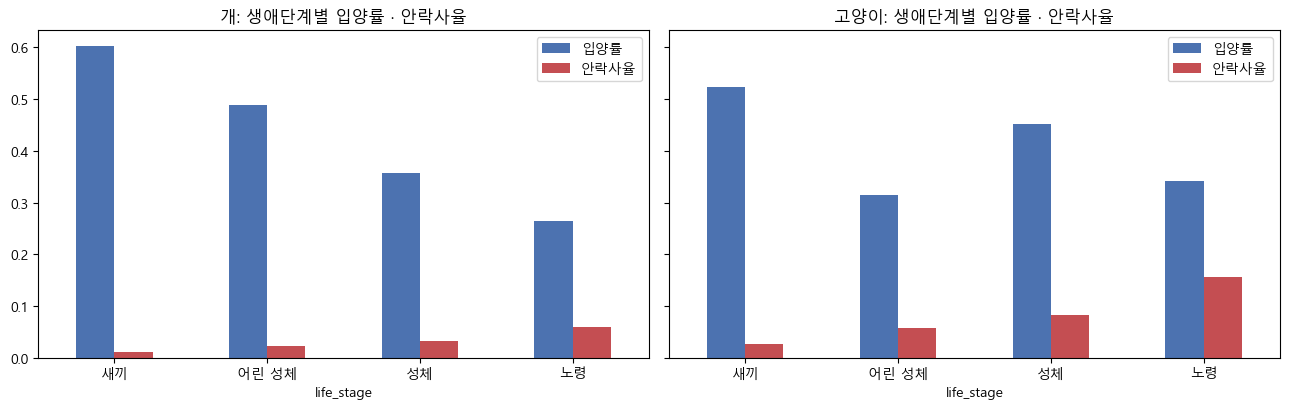

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
order = ["새끼", "어린 성체", "성체", "노령"]
for ax, t in zip(axes, ["Dog", "Cat"]):
    sub = df[df["animal_type"] == t]
    r = sub.groupby("life_stage")[["target_adoption", "target_euthanasia"]].mean().reindex(order)
    r.plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"], rot=0)
    ax.set_title(f"{'개' if t == 'Dog' else '고양이'}: 생애단계별 입양률 · 안락사율")
    ax.legend(["입양률", "안락사율"])
plt.tight_layout()
savefig("02_life_stage_by_species.png")
plt.show()

## 7. 분석 대상 · 데이터 분할 · 전처리 파이프라인 【문제 2, 7】
- **분할**: 기존과 같이 `GroupShuffleSplit`(Animal ID 기준, 8:2)을 전체 데이터에 한 번 적용하고, 개·고양이 데이터는 그 부분집합으로 사용합니다. 그래서 전체 동물 모델과 개·고양이 모델의 test 개체가 일치합니다.
- **전처리 파이프라인**: 원-핫 인코딩과 '상위 15개 품종·색상 + 기타' 묶기를 `ColumnTransformer`로 만들어 **train(또는 CV 학습 폴드)에서만 학습**합니다. 기존에는 분할 전 전체 데이터로 상위 15개를 골랐습니다.

In [8]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(df, groups=df["Animal ID"]))
df["split"] = "train"
df.iloc[te_idx, df.columns.get_loc("split")] = "test"

train_all, test_all = df[df["split"] == "train"], df[df["split"] == "test"]
is_dc = df["animal_type"].isin(["Dog", "Cat"])
train_dc, test_dc = df[is_dc & (df["split"] == "train")], df[is_dc & (df["split"] == "test")]

print("train/test 중복 Animal ID:", len(set(train_all["Animal ID"]) & set(test_all["Animal ID"])))
print(pd.DataFrame({
    "행 수": [len(train_all), len(test_all), len(train_dc), len(test_dc)],
    "입양률": [train_all.target_adoption.mean(), test_all.target_adoption.mean(),
             train_dc.target_adoption.mean(), test_dc.target_adoption.mean()],
    "안락사율": [train_all.target_euthanasia.mean(), test_all.target_euthanasia.mean(),
              train_dc.target_euthanasia.mean(), test_dc.target_euthanasia.mean()],
}, index=["전체 train", "전체 test", "개·고양이 train", "개·고양이 test"]).round(4).to_string())

train/test 중복 Animal ID: 0
               행 수     입양률    안락사율
전체 train     98259  0.4451  0.0672
전체 test      24676  0.4444  0.0673
개·고양이 train  92556  0.4663  0.0316
개·고양이 test   23237  0.4652  0.0317


In [9]:
HIGH_CARD = ["Breed_intake", "Color_intake"]
BASE_CAT = ["animal_type", "sex", "sterilized_status", "Intake Type", "Intake Condition",
            "breed_group", "life_stage", "Breed_intake", "Color_intake"]
BASE_NUM = ["age_days", "intake_month", "is_mixed_breed", "is_multicolor"]

for c in ["Breed_intake", "Color_intake", "Intake Condition", "Intake Type"]:
    df[c] = df[c].fillna("Unknown")
train_all, test_all = df[df["split"] == "train"], df[df["split"] == "test"]
train_dc, test_dc = df[is_dc & (df["split"] == "train")], df[is_dc & (df["split"] == "test")]


def feature_set(name_col="has_original_name", season=True):
    cat = BASE_CAT + (["intake_season"] if season else [])
    num = BASE_NUM + ([name_col] if name_col else [])
    return cat, num


def make_prep(cat, num, scale=False):
    low = [c for c in cat if c not in HIGH_CARD]
    high = [c for c in cat if c in HIGH_CARD]
    return ColumnTransformer([
        ("low", OneHotEncoder(handle_unknown="ignore", sparse_output=False), low),
        ("high", OneHotEncoder(max_categories=16, handle_unknown="infrequent_if_exist", sparse_output=False), high),
        ("num", StandardScaler() if scale else "passthrough", num),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


def make_model(kind, cat, num, **params):
    if kind == "LR":
        est = LogisticRegression(max_iter=3000, class_weight="balanced")
        return Pipeline([("prep", make_prep(cat, num, scale=True)), ("model", est)])
    if kind == "RF":
        est = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced",
                                     n_jobs=-1, random_state=SEED)
    else:
        kw = dict(random_state=SEED, class_weight="balanced", verbose=-1)
        kw.update(params)
        est = LGBMClassifier(**kw)
    return Pipeline([("prep", make_prep(cat, num)), ("model", est)])


# ---------- 평가 도구 ----------
def cv_splitter(n_splits=5, seed=SEED):
    return StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)


def oof_predict(pipe, X, y, groups, n_splits=5):
    # 동물 ID 단위 교차검증의 out-of-fold 예측 확률과 폴드별 PR-AUC
    oof = np.zeros(len(y))
    fold_ap = []
    for tr, va in cv_splitter(n_splits).split(X, y, groups):
        m = clone(pipe).fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]
        fold_ap.append(average_precision_score(y.iloc[va], oof[va]))
    return oof, np.array(fold_ap)


def threshold_for_recall(y, p, target=0.8):
    # Recall >= target 을 만족하는 임곗값 중 Precision이 가장 높은 값
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]
    ok = np.where(rec >= target)[0]
    return thr[ok[np.argmax(prec[ok])]]


def precision_at_recall(y, p, target=0.8):
    prec, rec, _ = precision_recall_curve(y, p)
    return prec[rec >= target].max()


def scores(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Recall": recall_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred)}

## 8. 변수 선택 실험 (Ablation) 【문제 4, 7 / 교수님 코멘트 7】
개·고양이 train에서 LightGBM으로 **동물 ID 기준 5-fold 교차검증**을 수행해, 변수 구성에 따른 PR-AUC를 비교합니다. (test는 사용하지 않습니다.)

| 설정 | 이름 변수 | 계절 |
|---|---|---|
| 기준 | `has_original_name` | 포함 |
| 기존 변수 | `has_name` (보호소 부여 이름 포함) | 포함 |
| 이름 제외 | 없음 | 포함 |
| 계절 제외 | `has_original_name` | 제외 |

In [10]:
configs = {
    "기준 (원래 이름 + 계절)": ("has_original_name", True),
    "기존 변수 has_name": ("has_name", True),
    "이름 변수 제외": (None, True),
    "계절 제외": ("has_original_name", False),
}
groups_dc = train_dc["Animal ID"]
abl_rows = []
for target, tname in [("target_adoption", "입양"), ("target_euthanasia", "안락사")]:
    for label, (nc, season) in configs.items():
        cat, num = feature_set(nc, season)
        _, ap = oof_predict(make_model("LGBM", cat, num), train_dc[cat + num], train_dc[target], groups_dc)
        abl_rows.append({"타깃": tname, "설정": label, "CV PR-AUC 평균": ap.mean(), "폴드 표준편차": ap.std()})
abl = pd.DataFrame(abl_rows)
display(abl.round(4))

,타깃,설정,CV PR-AUC 평균,폴드 표준편차
0,입양,기준 (원래 이름 + 계절),0.7341,0.0034
1,입양,기존 변수 has_name,0.7433,0.0033
2,입양,이름 변수 제외,0.7090,0.0034
3,입양,계절 제외,0.7337,0.0040
4,안락사,기준 (원래 이름 + 계절),0.3392,0.0194
5,안락사,기존 변수 has_name,0.3903,0.0239
6,안락사,이름 변수 제외,0.3193,0.0167
7,안락사,계절 제외,0.3397,0.0178


In [11]:
def abl_value(tname, label):
    r = abl[(abl["타깃"] == tname) & (abl["설정"] == label)].iloc[0]
    return r["CV PR-AUC 평균"], r["폴드 표준편차"]

# (1) 이름 변수: 보호소 부여 이름을 포함하면 성능이 얼마나 부풀려지는가
for tname in ["입양", "안락사"]:
    base, _ = abl_value(tname, "기준 (원래 이름 + 계절)")
    star, _ = abl_value(tname, "기존 변수 has_name")
    none, _ = abl_value(tname, "이름 변수 제외")
    print(f"[{tname}] has_name {star:.4f} | has_original_name {base:.4f} | 이름 제외 {none:.4f}")

# (2) 계절 변수: 1개 이상 타깃에서 폴드 표준편차보다 크게 성능을 높이면 유지
season_gain = {}
for tname in ["입양", "안락사"]:
    base, sd = abl_value(tname, "기준 (원래 이름 + 계절)")
    no_season, _ = abl_value(tname, "계절 제외")
    season_gain[tname] = (base - no_season, sd)
KEEP_SEASON = any(g > sd for g, sd in season_gain.values())
for k, (g, sd) in season_gain.items():
    print(f"[{k}] 계절 포함 효과 {g:+.4f} (폴드 표준편차 {sd:.4f})")

NAME_COL = "has_original_name"   # 누수 위험이 낮은 변수만 사용
FINAL_CAT, FINAL_NUM = feature_set(NAME_COL, KEEP_SEASON)
FEATS = FINAL_CAT + FINAL_NUM
print("\n계절 변수 유지:", KEEP_SEASON)
print("최종 특성:", FEATS)

[입양] has_name 0.7433 | has_original_name 0.7341 | 이름 제외 0.7090
[안락사] has_name 0.3903 | has_original_name 0.3392 | 이름 제외 0.3193
[입양] 계절 포함 효과 +0.0003 (폴드 표준편차 0.0034)
[안락사] 계절 포함 효과 -0.0005 (폴드 표준편차 0.0194)

계절 변수 유지: False
최종 특성: ['animal_type', 'sex', 'sterilized_status', 'Intake Type', 'Intake Condition', 'breed_group', 'life_stage', 'Breed_intake', 'Color_intake', 'age_days', 'intake_month', 'is_mixed_breed', 'is_multicolor', 'has_original_name']


**결과 해석**
- **이름 변수**: 보호소가 붙인 이름까지 포함한 `has_name`을 쓰면 안락사 CV PR-AUC가 0.339 → 0.390으로 **약 0.05 높아집니다**. 그런데 보호소가 이름을 붙인 동물(`*`)은 입양률 66.7%, 안락사율 1.3%로, 원래 이름이 있던 동물(45.5%, 2.2%)보다도 결과가 좋습니다. 이는 **입양 절차가 진행되는 동물에게 이름이 붙는다**는 뜻이므로, 늘어난 0.05는 결과 정보가 새어 들어온(누수) 성능으로 판단합니다. 따라서 `has_original_name`을 사용합니다. 원래 이름 여부 자체는 유효한 신호입니다(제외하면 입양 0.734 → 0.709).
- **계절 변수**: 포함했을 때 효과가 입양 +0.0003, 안락사 −0.0005로, 폴드 간 표준편차(0.003~0.019)보다 훨씬 작습니다. 교수님 코멘트 7의 기준에 따라 **계절 변수를 제외**합니다.

## 9. 입양 예측 모델 (개·고양이) 【문제 6】
기존에는 발표자료의 입양 모델(튜닝·SHAP)이 이 폴더의 노트북에 없었습니다. 여기서 **기준 모델 3종 비교 → LightGBM 튜닝 → SHAP 해석**을 한 번에 수행합니다.

In [12]:
Xtr, Xte = train_dc[FEATS], test_dc[FEATS]
ya_tr, ya_te = train_dc["target_adoption"], test_dc["target_adoption"]
ye_tr, ye_te = train_dc["target_euthanasia"], test_dc["target_euthanasia"]


def adoption_row(name, p):
    pred = (p >= 0.5).astype(int)
    return {"Model": name, "ROC-AUC": roc_auc_score(ya_te, p), "PR-AUC": average_precision_score(ya_te, p),
            "Accuracy": accuracy_score(ya_te, pred),
            "비입양 Recall": recall_score(ya_te, pred, pos_label=0),
            "비입양 Precision": precision_score(ya_te, pred, pos_label=0)}


adopt_rows, adopt_proba = [], {}
for kind, label in [("LR", "Logistic Regression"), ("RF", "Random Forest"), ("LGBM", "LightGBM (기본)")]:
    m = make_model(kind, FINAL_CAT, FINAL_NUM).fit(Xtr, ya_tr)
    adopt_proba[label] = m.predict_proba(Xte)[:, 1]
    adopt_rows.append(adoption_row(label, adopt_proba[label]))
display(pd.DataFrame(adopt_rows).round(4))

,Model,ROC-AUC,PR-AUC,Accuracy,비입양 Recall,비입양 Precision
0,Logistic Regression,0.7172,0.6405,0.6589,0.5985,0.7170
1,Random Forest,0.7728,0.7217,0.7045,0.6757,0.7475
2,LightGBM (기본),0.7757,0.7258,0.7093,0.6497,0.7707


In [13]:
param_dist = {
    "model__num_leaves": [15, 31, 63, 127],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__n_estimators": [200, 400, 700],
    "model__min_child_samples": [10, 20, 50, 100],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__subsample_freq": [1],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__reg_lambda": [0, 1, 5],
}
search = RandomizedSearchCV(make_model("LGBM", FINAL_CAT, FINAL_NUM), param_dist, n_iter=12,
                            scoring="average_precision", cv=cv_splitter(3), random_state=SEED,
                            n_jobs=1, refit=True)
search.fit(Xtr, ya_tr, groups=train_dc["Animal ID"])
BEST_ADOPT_PARAMS = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("최적 하이퍼파라미터:", BEST_ADOPT_PARAMS)
print(f"CV PR-AUC: {search.best_score_:.4f}")

adopt_final = search.best_estimator_
adopt_proba["LightGBM (튜닝)"] = adopt_final.predict_proba(Xte)[:, 1]
adopt_rows.append(adoption_row("LightGBM (튜닝)", adopt_proba["LightGBM (튜닝)"]))
adopt_table = pd.DataFrame(adopt_rows)
display(adopt_table.round(4))

최적 하이퍼파라미터: {'subsample_freq': 1, 'subsample': 1.0, 'reg_lambda': 1, 'num_leaves': 127, 'n_estimators': 400, 'min_child_samples': 10, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
CV PR-AUC: 0.7436


,Model,ROC-AUC,PR-AUC,Accuracy,비입양 Recall,비입양 Precision
0,Logistic Regression,0.7172,0.6405,0.6589,0.5985,0.7170
1,Random Forest,0.7728,0.7217,0.7045,0.6757,0.7475
2,LightGBM (기본),0.7757,0.7258,0.7093,0.6497,0.7707
3,LightGBM (튜닝),0.7834,0.7404,0.7137,0.6635,0.7695


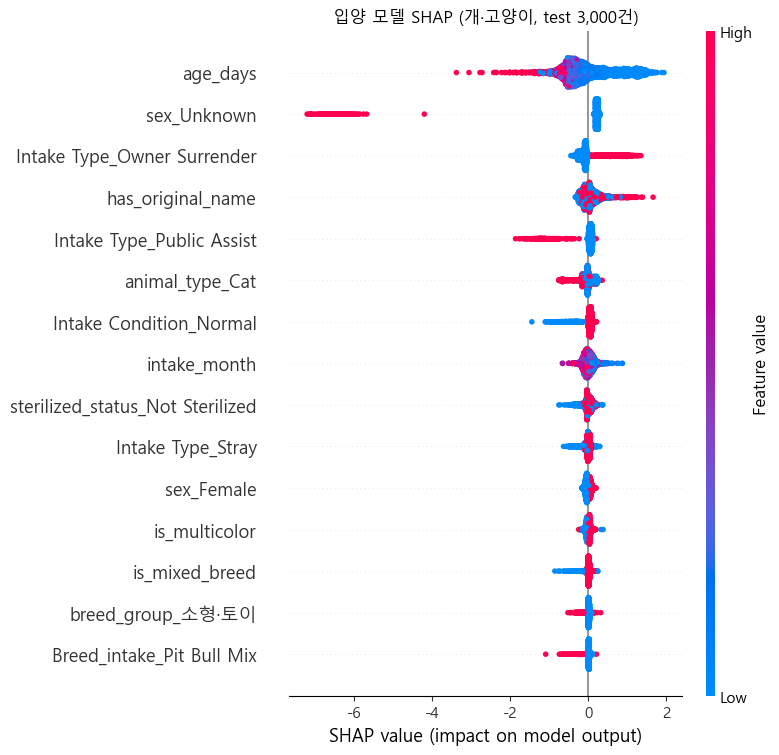

,feature,mean|SHAP|,방향(값↑→입양확률)
0,age_days,0.5537,감소
1,sex_Unknown,0.4745,감소
2,Intake Type_Owner Surrender,0.2307,증가
3,has_original_name,0.1677,증가
4,Intake Type_Public Assist,0.1301,감소
5,animal_type_Cat,0.1200,감소
6,Intake Condition_Normal,0.1037,증가
7,intake_month,0.0958,감소
8,sterilized_status_Not Sterilized,0.0831,증가
9,Intake Type_Stray,0.0555,증가


In [14]:
import shap

prep_a, lgbm_a = adopt_final.named_steps["prep"], adopt_final.named_steps["model"]
X_shap = prep_a.transform(Xte.sample(3000, random_state=SEED))
sv = shap.TreeExplainer(lgbm_a).shap_values(X_shap)
if isinstance(sv, list):
    sv = sv[1]
if sv.ndim == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv, X_shap, max_display=15, show=False)
plt.title("입양 모델 SHAP (개·고양이, test 3,000건)")
savefig("03_adoption_shap.png")
plt.show()

imp = pd.DataFrame({"feature": X_shap.columns, "mean|SHAP|": np.abs(sv).mean(axis=0)})
direction = []
for i, c in enumerate(X_shap.columns):
    x = X_shap[c].astype(float).values
    direction.append(np.corrcoef(x, sv[:, i])[0, 1] if x.std() > 0 else np.nan)
imp["방향(값↑→입양확률)"] = np.where(np.array(direction) > 0, "증가", "감소")
adopt_shap_top = imp.sort_values("mean|SHAP|", ascending=False).head(10).reset_index(drop=True)
display(adopt_shap_top.round(4))

**결과 해석 (입양 모델)**
- 튜닝한 LightGBM이 가장 좋습니다: ROC-AUC **0.783**, 비입양 Recall **0.664**, 비입양 Precision **0.770**.
- 발표자료(0.692 / 0.797)보다 조금 낮습니다. 개선판은 (1) 비입양을 맞히기 쉬운 야생동물을 빼고 개·고양이만 사용하고, (2) 누수 가능성이 있는 `has_name`을 `has_original_name`으로 바꿨기 때문입니다. **더 보수적이지만 실제 운영에 가까운 수치**입니다.
- SHAP 주요 요인: 나이↑ → 입양↓, **성별 미확인** → 입양↓, 소유자 인계 → 입양↑, 원래 이름 있음 → 입양↑, Public Assist(주인 찾기 목적의 입소) → 입양↓. 모두 연관성이며 인과가 아닙니다.

## 10. 안락사 위험 모델 【문제 1, 2】
### 10-1. 전체 동물 모델 vs 개·고양이 모델
전체 동물로 학습한 모델의 성능이 어디서 나오는지 분해하고, 단순 규칙(“야생동물·기타 동물이면 안락사”)과 비교합니다.

In [15]:
m_all = make_model("LGBM", FINAL_CAT, FINAL_NUM).fit(train_all[FEATS], train_all["target_euthanasia"])
p_all = m_all.predict_proba(test_all[FEATS])[:, 1]
y_all = test_all["target_euthanasia"].values
oth = (test_all["animal_type"] == "Other").values
rule = ((test_all["animal_type"] == "Other") | (test_all["Intake Type"] == "Wildlife")).astype(float).values

m_dc = make_model("LGBM", FINAL_CAT, FINAL_NUM).fit(Xtr, ye_tr)
p_dc = m_dc.predict_proba(Xte)[:, 1]

scope = pd.DataFrame([
    {"평가 대상": "전체 동물 test", "모델": "전체 동물 LGBM", "안락사 비율": y_all.mean(),
     "PR-AUC": average_precision_score(y_all, p_all), "ROC-AUC": roc_auc_score(y_all, p_all)},
    {"평가 대상": "전체 동물 test", "모델": "규칙: Other 또는 Wildlife", "안락사 비율": y_all.mean(),
     "PR-AUC": average_precision_score(y_all, rule), "ROC-AUC": roc_auc_score(y_all, rule)},
    {"평가 대상": "Other만", "모델": "전체 동물 LGBM", "안락사 비율": y_all[oth].mean(),
     "PR-AUC": average_precision_score(y_all[oth], p_all[oth]), "ROC-AUC": roc_auc_score(y_all[oth], p_all[oth])},
    {"평가 대상": "개·고양이만", "모델": "전체 동물 LGBM", "안락사 비율": y_all[~oth].mean(),
     "PR-AUC": average_precision_score(y_all[~oth], p_all[~oth]), "ROC-AUC": roc_auc_score(y_all[~oth], p_all[~oth])},
    {"평가 대상": "개·고양이만", "모델": "개·고양이 전용 LGBM", "안락사 비율": ye_te.mean(),
     "PR-AUC": average_precision_score(ye_te, p_dc), "ROC-AUC": roc_auc_score(ye_te, p_dc)},
])
display(scope.round(4))

,평가 대상,모델,안락사 비율,PR-AUC,ROC-AUC
0,전체 동물 test,전체 동물 LGBM,0.0673,0.7315,0.9372
1,전체 동물 test,규칙: Other 또는 Wildlife,0.0673,0.3865,0.7668
2,Other만,전체 동물 LGBM,0.6414,0.9093,0.9022
3,개·고양이만,전체 동물 LGBM,0.0317,0.3285,0.8689
4,개·고양이만,개·고양이 전용 LGBM,0.0317,0.3322,0.8697


**결과 해석**
- 전체 동물 모델의 PR-AUC 0.73은 대부분 **Other(야생동물)** 에서 나옵니다. Other만 보면 0.91이지만 개·고양이만 보면 **0.33**입니다. "Other이거나 Wildlife면 안락사"라는 규칙 하나만으로도 0.39가 나옵니다.
- 개·고양이 전용 모델도 0.332로 비슷합니다. 따라서 이 수치가 **보호소가 실제로 개입할 수 있는 동물에 대한 현실적인 성능**입니다. 무작위로 순위를 매겼을 때의 기준선(안락사 비율 3.2%)보다 약 10배 높으므로, 위험 순위 정보로는 여전히 의미가 있습니다.
- 이후 안락사 분석은 모두 **개·고양이** 기준으로 진행합니다.

### 10-2. 직접모델 vs 2단계 모델 — 공정한 비교 (교차검증으로 선택)
두 전략을 **같은 대상(개·고양이 전체)**, **같은 점수 형태**로 비교합니다.
- 직접모델 점수: `P(안락사)`
- 2단계 점수: `(1 − P(입양)) × P(안락사 | 비입양)` — 발표자료의 우선순위 점수와 같음

각 CV 폴드 안에서 입양 모델(튜닝 파라미터), 직접모델, 2단계 모델을 모두 학습 폴드로만 학습하므로 누수가 없습니다. **전략 선택은 CV 결과로 하고, test는 확인용으로만 사용**합니다.

In [16]:
oof_direct = np.zeros(len(Xtr))
oof_pipe = np.zeros(len(Xtr))
fold_rows = []
for k, (tr, va) in enumerate(cv_splitter(5).split(Xtr, ye_tr, groups_dc)):
    X_a, X_v = Xtr.iloc[tr], Xtr.iloc[va]
    d = make_model("LGBM", FINAL_CAT, FINAL_NUM).fit(X_a, ye_tr.iloc[tr])
    a = make_model("LGBM", FINAL_CAT, FINAL_NUM, **BEST_ADOPT_PARAMS).fit(X_a, ya_tr.iloc[tr])
    non_adopt = (ya_tr.iloc[tr] == 0).values
    s2 = make_model("LGBM", FINAL_CAT, FINAL_NUM).fit(X_a[non_adopt], ye_tr.iloc[tr][non_adopt])
    oof_direct[va] = d.predict_proba(X_v)[:, 1]
    oof_pipe[va] = (1 - a.predict_proba(X_v)[:, 1]) * s2.predict_proba(X_v)[:, 1]
    fold_rows.append({"fold": k + 1,
                      "직접 PR-AUC": average_precision_score(ye_tr.iloc[va], oof_direct[va]),
                      "2단계 PR-AUC": average_precision_score(ye_tr.iloc[va], oof_pipe[va])})
folds = pd.DataFrame(fold_rows)
folds["차이(2단계-직접)"] = folds["2단계 PR-AUC"] - folds["직접 PR-AUC"]
display(folds.round(4))

diff_mean, diff_sd = folds["차이(2단계-직접)"].mean(), folds["차이(2단계-직접)"].std()
print(f"평균 차이 {diff_mean:+.4f} (폴드 표준편차 {diff_sd:.4f})")
if diff_mean > diff_sd:
    FINAL_EUTH_STRATEGY = "2단계"
elif diff_mean < -diff_sd:
    FINAL_EUTH_STRATEGY = "직접"
else:
    FINAL_EUTH_STRATEGY = "직접"   # 차이가 폴드 변동 이내 → 모델 1개로 단순한 직접모델 선택
print("선택된 안락사 전략:", FINAL_EUTH_STRATEGY)

,fold,직접 PR-AUC,2단계 PR-AUC,차이(2단계-직접)
0,1,0.3405,0.3305,-0.0100
1,2,0.3673,0.3460,-0.0213
2,3,0.3381,0.3266,-0.0115
3,4,0.3112,0.3188,0.0076
4,5,0.3415,0.3239,-0.0176


평균 차이 -0.0106 (폴드 표준편차 0.0111)
선택된 안락사 전략: 직접


In [17]:
# test 확인: 모델 3종 × 전략 2종, 모두 개·고양이 test 전체에서 같은 기준으로 평가
p_adopt_te = adopt_proba["LightGBM (튜닝)"]
non_adopt_tr = (ya_tr == 0).values
non_adopt_te = (ya_te == 0).values

euth_rows, euth_scores = [], {}
for kind, label in [("LR", "Logistic Regression"), ("RF", "Random Forest"), ("LGBM", "LightGBM")]:
    d = make_model(kind, FINAL_CAT, FINAL_NUM).fit(Xtr, ye_tr)
    s2 = make_model(kind, FINAL_CAT, FINAL_NUM).fit(Xtr[non_adopt_tr], ye_tr[non_adopt_tr])
    p_d = d.predict_proba(Xte)[:, 1]
    p_s2 = s2.predict_proba(Xte)[:, 1]
    p_p = (1 - p_adopt_te) * p_s2
    euth_scores[(label, "직접")] = p_d
    euth_scores[(label, "2단계")] = p_p
    for strat, p, p_cond in [("직접", p_d, p_d), ("2단계", p_p, p_s2)]:
        euth_rows.append({
            "Model": label, "Strategy": strat,
            "PR-AUC (전체 test)": average_precision_score(ye_te, p),
            "ROC-AUC (전체 test)": roc_auc_score(ye_te, p),
            "Precision@Recall0.8": precision_at_recall(ye_te, p),
            "PR-AUC (비입양 test만·참고)": average_precision_score(ye_te[non_adopt_te], p_cond[non_adopt_te]),
        })
euth_table = pd.DataFrame(euth_rows)
display(euth_table.round(4))
print(f"개·고양이 test 안락사 비율: {ye_te.mean():.2%} | 비입양 test 내 안락사 비율: {ye_te[non_adopt_te].mean():.2%}")

,Model,Strategy,PR-AUC (전체 test),ROC-AUC (전체 test),Precision@Recall0.8,PR-AUC (비입양 test만·참고)
0,Logistic Regression,직접,0.2588,0.8406,0.0822,0.3244
1,Logistic Regression,2단계,0.2530,0.8314,0.0778,0.3282
2,Random Forest,직접,0.2479,0.8470,0.0913,0.3265
3,Random Forest,2단계,0.2900,0.8565,0.0909,0.3506
4,LightGBM,직접,0.3322,0.8697,0.1084,0.3992
5,LightGBM,2단계,0.3015,0.8636,0.0980,0.4084


개·고양이 test 안락사 비율: 3.17% | 비입양 test 내 안락사 비율: 5.93%


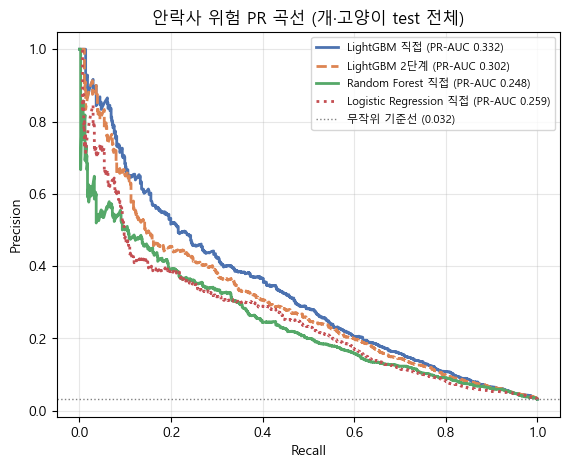

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for (label, strat), color, ls in [(("LightGBM", "직접"), "#4C72B0", "-"), (("LightGBM", "2단계"), "#DD8452", "--"),
                                  (("Random Forest", "직접"), "#55A868", "-"), (("Logistic Regression", "직접"), "#C44E52", ":")]:
    p = euth_scores[(label, strat)]
    prec, rec, _ = precision_recall_curve(ye_te, p)
    ax.plot(rec, prec, color=color, ls=ls, lw=2, label=f"{label} {strat} (PR-AUC {average_precision_score(ye_te, p):.3f})")
ax.axhline(ye_te.mean(), color="gray", lw=1, ls=":", label=f"무작위 기준선 ({ye_te.mean():.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("안락사 위험 PR 곡선 (개·고양이 test 전체)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
savefig("04_euthanasia_pr_curves.png")
plt.show()

**결과 해석**
- **교차검증**: 2단계 점수가 직접모델보다 평균 0.011 낮았고, 이 차이는 폴드 간 표준편차(0.011) 수준이라 2단계의 우위가 없습니다. 그래서 **직접모델을 채택**합니다. 모델이 하나라 단순하고, 입양 모델의 오류가 안락사 점수로 옮겨가지도 않습니다.
- **test 확인**: 같은 기준으로 비교하면 LightGBM 직접모델 0.332, 2단계 0.302로 직접모델이 약간 높습니다. 모델 3종 중에서는 LightGBM이 가장 좋습니다.
- **착시 재현**: 마지막 열(비입양 test만)처럼 2단계를 비입양 동물로만 평가하면 0.408로 더 좋아 보입니다. 양성 비율이 5.9%로 3.2%보다 높기 때문이며, 기존 노트북의 0.777 vs 0.746도 같은 원리의 착시였습니다.
- **운영 제안**: 우선순위 점수로는 직접모델의 P(안락사)를 쓰고, 입양 모델의 P(입양)과 함께 **2차원(입양 가능성 × 안락사 위험)** 으로 보여주는 방식을 권장합니다.

## 11. 불균형 대응 전략 비교 【문제 5】
기존 step 12의 세 가지 빈틈을 고쳤습니다.

| 기존 | 개선 |
|---|---|
| `RepeatedStratifiedKFold` (같은 동물이 학습·검증 폴드에 섞임) | **`StratifiedGroupKFold`** (동물 ID 단위) |
| 임곗값을 **학습 데이터 예측**으로 결정 | 임곗값을 **OOF(검증 폴드) 예측**으로 결정 → test에 그대로 적용 |
| 원-핫 데이터에 **SMOTE** (0.37 같은 값 생성) | 원본 범주형에 **SMOTENC** 적용 후 원-핫 (학습 폴드 안에서만) |

대상: 개·고양이 **안락사 직접모델**(LightGBM). 목표 Recall = 0.8.

In [19]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

cont_cols = ["age_days"]
smote_cat_idx = [i for i, c in enumerate(FEATS) if c not in cont_cols]   # 0/1 변수와 월도 범주로 취급 → 소수점 값 방지

strategies = {
    "가중치 없음": make_model("LGBM", FINAL_CAT, FINAL_NUM, class_weight=None),
    "class_weight=balanced": make_model("LGBM", FINAL_CAT, FINAL_NUM),
    "SMOTENC (폴드 내부)": ImbPipeline([
        ("smote", SMOTENC(categorical_features=smote_cat_idx, random_state=SEED)),
        ("prep", make_prep(FINAL_CAT, FINAL_NUM)),
        ("model", LGBMClassifier(random_state=SEED, verbose=-1)),
    ]),
}

imb_rows, imb_thr = [], {}
for name, pipe in strategies.items():
    oof, ap = oof_predict(pipe, Xtr, ye_tr, groups_dc)
    thr = threshold_for_recall(ye_tr, oof, 0.8)          # OOF 예측으로 임곗값 결정
    imb_thr[name] = thr
    p_te = clone(pipe).fit(Xtr, ye_tr).predict_proba(Xte)[:, 1]
    pred_thr, pred_05 = (p_te >= thr).astype(int), (p_te >= 0.5).astype(int)
    imb_rows.append({
        "전략": name, "CV PR-AUC": ap.mean(), "CV 표준편차": ap.std(), "OOF 임곗값": thr,
        "test PR-AUC": average_precision_score(ye_te, p_te),
        "test Recall@OOF임곗값": recall_score(ye_te, pred_thr),
        "test Precision@OOF임곗값": precision_score(ye_te, pred_thr),
        "test Recall@0.5": recall_score(ye_te, pred_05),
        "test Precision@0.5": precision_score(ye_te, pred_05, zero_division=0),
    })
imb_table = pd.DataFrame(imb_rows)
display(imb_table.round(4))

,전략,CV PR-AUC,CV 표준편차,OOF 임곗값,test PR-AUC,test Recall@OOF임곗값,test Precision@OOF임곗값,test Recall@0.5,test Precision@0.5
0,가중치 없음,0.3432,0.0154,0.0213,0.3206,0.8141,0.1007,0.0977,0.6729
1,class_weight=balanced,0.3397,0.0178,0.3789,0.3322,0.8155,0.1024,0.7286,0.1435
2,SMOTENC (폴드 내부),0.2853,0.0127,0.2090,0.2631,0.8046,0.0785,0.5699,0.1757


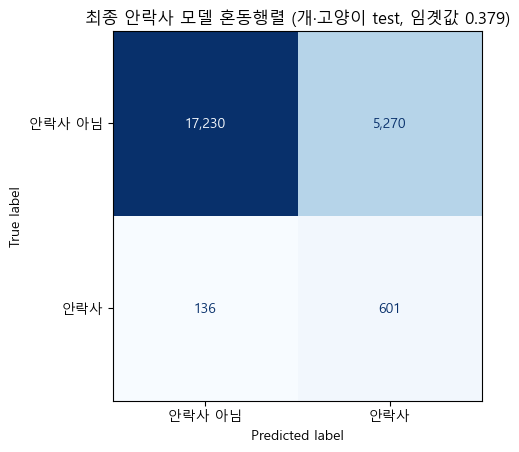

In [20]:
# 최종 안락사 모델: class_weight=balanced LightGBM + OOF 임곗값
EUTH_THR = imb_thr["class_weight=balanced"]
p_final_euth = euth_scores[("LightGBM", "직접")]
cm = confusion_matrix(ye_te, (p_final_euth >= EUTH_THR).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["안락사 아님", "안락사"]).plot(cmap="Blues", values_format=",d", colorbar=False)
plt.title(f"최종 안락사 모델 혼동행렬 (개·고양이 test, 임곗값 {EUTH_THR:.3f})")
plt.grid(False)
savefig("05_euthanasia_confusion.png")
plt.show()

**결과 해석**
- **SMOTENC**는 CV PR-AUC 0.285로 가장 낮아 사용하지 않습니다. **가중치 없음**(0.343)과 **balanced**(0.340)는 차이가 없습니다. PR-AUC는 순위만 보는 지표라 가중치의 영향을 거의 받지 않고, 가중치가 바꾸는 것은 **확률의 크기**입니다. 그래서 0.5를 기준으로 판정하면 Recall이 0.10과 0.73으로 크게 달라집니다.
- **OOF로 정한 임곗값(0.379)을 test에 그대로 적용해도 Recall 0.815**가 나옵니다. 즉 임곗값이 새로운 데이터에서도 유지됩니다. 학습 데이터로 임곗값을 정하던 기존 방식으로는 이것을 확인할 수 없었습니다.
- **현실적인 해석**: Recall 0.8에서 Precision은 약 0.10입니다. 입소 동물의 **약 25%를 검토 대상으로 표시하면 안락사의 82%가 그 안에 포함**됩니다. 개·고양이 안락사율이 3%라서 경보 10건 중 1건만 실제 안락사로 이어집니다. 따라서 이 모델은 자동 판정이 아니라 **집중 관리 대상을 추리는 스크리닝 도구**로 써야 합니다.

### 11-1. 안락사 모델 해석 (SHAP)

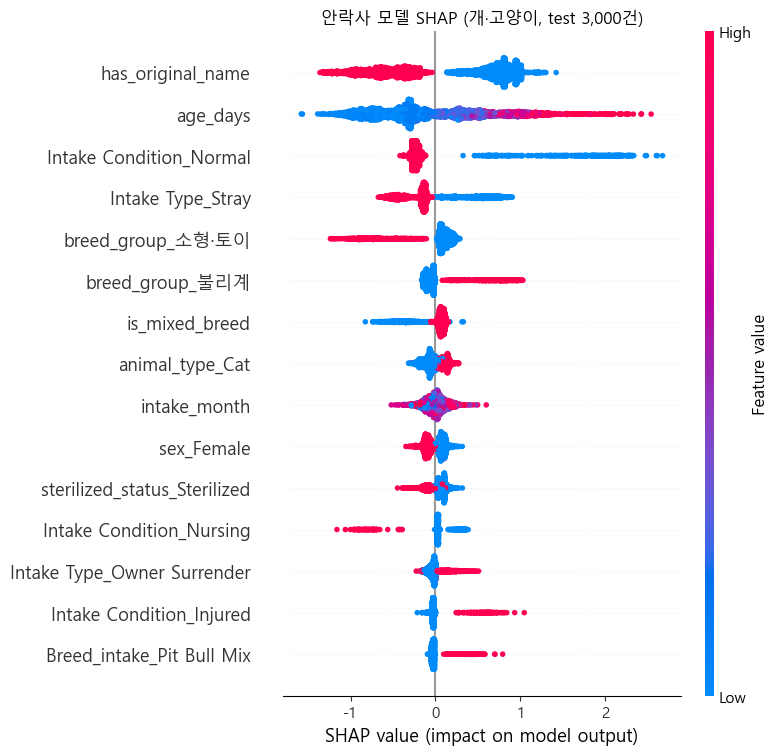

,feature,mean|SHAP|,방향(값↑→안락사위험)
0,has_original_name,0.6727,감소
1,age_days,0.5784,증가
2,Intake Condition_Normal,0.3931,감소
3,Intake Type_Stray,0.3116,감소
4,breed_group_소형·토이,0.2020,감소
5,breed_group_불리계,0.1457,증가
6,is_mixed_breed,0.1228,증가
7,animal_type_Cat,0.0919,증가
8,intake_month,0.0904,증가
9,sex_Female,0.0903,감소


In [21]:
prep_e, lgbm_e = m_dc.named_steps["prep"], m_dc.named_steps["model"]
X_shap_e = prep_e.transform(Xte.sample(3000, random_state=SEED))
sv_e = shap.TreeExplainer(lgbm_e).shap_values(X_shap_e)
if isinstance(sv_e, list):
    sv_e = sv_e[1]
if sv_e.ndim == 3:
    sv_e = sv_e[:, :, 1]
shap.summary_plot(sv_e, X_shap_e, max_display=15, show=False)
plt.title("안락사 모델 SHAP (개·고양이, test 3,000건)")
savefig("06_euthanasia_shap.png")
plt.show()

imp_e = pd.DataFrame({"feature": X_shap_e.columns, "mean|SHAP|": np.abs(sv_e).mean(axis=0)})
dir_e = [np.corrcoef(X_shap_e[c].astype(float), sv_e[:, i])[0, 1] if X_shap_e[c].std() > 0 else np.nan
         for i, c in enumerate(X_shap_e.columns)]
imp_e["방향(값↑→안락사위험)"] = np.where(np.array(dir_e) > 0, "증가", "감소")
euth_shap_top = imp_e.sort_values("mean|SHAP|", ascending=False).head(10).reset_index(drop=True)
display(euth_shap_top.round(4))

**결과 해석 (안락사 모델 SHAP)**
- 원래 이름 없음, 고령, 건강 상태 비정상이 위험을 높이는 주요 요인입니다. 유기(Stray) 입소는 소유자 인계나 안락사 요청 입소보다 위험이 낮습니다.
- 품종군에서는 소형·토이는 위험↓, 불리계는 위험↑로 나타납니다. 개 안락사 사유의 30%가 공격성(Aggressive)이라는 점과 관련 있어 보이지만, **품종이 원인이라는 뜻은 아니므로** 운영 기준으로 쓸 때 주의가 필요합니다.

## 12. 시간 기준 검증 【문제 7】
실제 운영에서는 **과거 데이터로 학습한 모델을 미래 입소 동물**에 적용합니다. 무작위 분할보다 현실적인 검증입니다.
- 학습: 2013-10 ~ 2018-12 입소 / 평가: 2019-01 ~ 2021-03 입소 (개·고양이)
- 학습 기간에 등장한 동물은 평가에서 제외 (개체 누수 방지)
- 입양 모델은 9장의 튜닝 파라미터, 안락사 모델은 11장의 OOF 임곗값을 **그대로** 사용
- 주의: 2021년 입소 중 데이터 추출 시점(2021-03)에 아직 보호 중인 동물은 빠져 있어, 최근 기간은 빨리 퇴소한 동물 위주입니다.

학습 87,851행 / 평가 26,267행


,평가 기간,행 수,입양률,입양 ROC-AUC,안락사율,안락사 PR-AUC,안락사 ROC-AUC,안락사 Recall@임곗값
0,2019~2021 전체,26267,0.5028,0.7417,0.0189,0.1901,0.8652,0.7907
1,2019,17369,0.4970,0.7458,0.0155,0.1666,0.8499,0.7259
2,2020,8256,0.5214,0.7323,0.0256,0.2179,0.8737,0.8578
3,2021,642,0.4174,0.7577,0.0249,0.3643,0.9449,1.0000


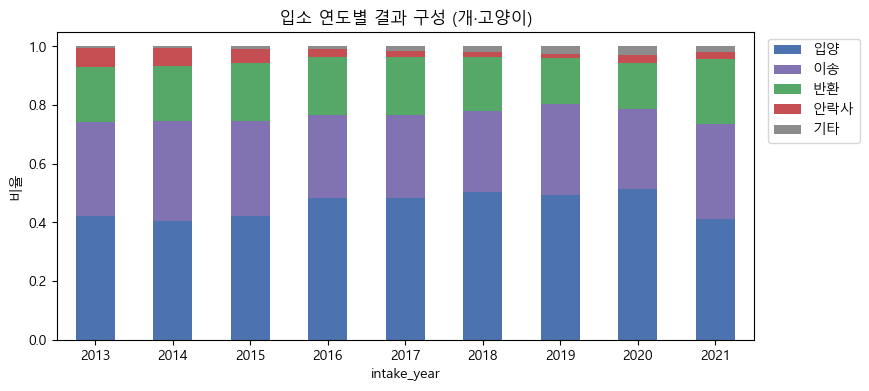

In [22]:
dc = df[is_dc]
CUT = pd.Timestamp("2019-01-01")
tr_t = dc[dc["DateTime_intake"] < CUT]
te_t = dc[(dc["DateTime_intake"] >= CUT) & ~dc["Animal ID"].isin(tr_t["Animal ID"])]
print(f"학습 {len(tr_t):,}행 / 평가 {len(te_t):,}행")

a_t = make_model("LGBM", FINAL_CAT, FINAL_NUM, **BEST_ADOPT_PARAMS).fit(tr_t[FEATS], tr_t["target_adoption"])
e_t = make_model("LGBM", FINAL_CAT, FINAL_NUM).fit(tr_t[FEATS], tr_t["target_euthanasia"])
te_t = te_t.assign(p_adopt=a_t.predict_proba(te_t[FEATS])[:, 1], p_euth=e_t.predict_proba(te_t[FEATS])[:, 1])

time_rows = []
for period, g in [("2019~2021 전체", te_t)] + [(str(y), g) for y, g in te_t.groupby("intake_year")]:
    time_rows.append({
        "평가 기간": period, "행 수": len(g),
        "입양률": g["target_adoption"].mean(),
        "입양 ROC-AUC": roc_auc_score(g["target_adoption"], g["p_adopt"]),
        "안락사율": g["target_euthanasia"].mean(),
        "안락사 PR-AUC": average_precision_score(g["target_euthanasia"], g["p_euth"]),
        "안락사 ROC-AUC": roc_auc_score(g["target_euthanasia"], g["p_euth"]),
        "안락사 Recall@임곗값": recall_score(g["target_euthanasia"], (g["p_euth"] >= EUTH_THR).astype(int)),
    })
time_table = pd.DataFrame(time_rows)
display(time_table.round(4))

yr = dc.groupby("intake_year")["outcome_category"].value_counts(normalize=True).unstack().fillna(0)
yr[["입양", "이송", "반환", "안락사", "기타"]].plot(kind="bar", stacked=True, figsize=(9, 4), rot=0,
                                            color=["#4C72B0", "#8172B2", "#55A868", "#C44E52", "#8C8C8C"])
plt.title("입소 연도별 결과 구성 (개·고양이)")
plt.ylabel("비율"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
savefig("07_outcome_by_year.png")
plt.show()

**결과 해석**
- **입양 모델**: ROC-AUC가 0.783(무작위 분할)에서 **0.742**로 떨어집니다. 미래에 적용하면 성능이 다소 낮아집니다.
- **안락사 모델**: ROC-AUC는 0.87 → **0.865**로 유지됩니다. PR-AUC가 0.33 → 0.19로 떨어진 것은 이 기간의 안락사율이 3.2% → **1.9%로 줄었기 때문**이며, 기준선 대비 약 10배라는 점은 그대로입니다.
- **같은 임곗값에서의 Recall**: 2019년 0.73, 2020년 0.86으로 **연도마다 흔들립니다**. 코로나 시기에는 결과 구성도 바뀌었습니다(그림 7). 발표자료의 "월별 Recall 재평가" 원칙이 실제로 필요하다는 근거입니다. 2021년은 642건뿐이고 아직 보호 중인 동물이 빠져 있어 해석에 주의해야 합니다.

## 13. 최종 요약 — 기존 vs 개선

In [23]:
lgb_d = euth_table[(euth_table.Model == "LightGBM") & (euth_table.Strategy == "직접")].iloc[0]
lgb_p = euth_table[(euth_table.Model == "LightGBM") & (euth_table.Strategy == "2단계")].iloc[0]
bal = imb_table[imb_table["전략"] == "class_weight=balanced"].iloc[0]
tuned = adopt_table[adopt_table.Model == "LightGBM (튜닝)"].iloc[0]
t_all = time_table.iloc[0]

summary = pd.DataFrame([
    ["병합 · 체류기간 음수 행", "694행", f"{(new_los < 0).sum()}행"],
    ["안락사 평가 대상", "전체 동물 (야생동물 포함)", "개·고양이 (야생동물은 규칙으로 분리)"],
    ["안락사 전략 비교 기준", "서로 다른 집단 (6.9% vs 12.5%)", "같은 test 전체 + 동물 ID CV"],
    ["안락사 PR-AUC · LightGBM 직접", "0.746 (전체 동물)", f"{lgb_d['PR-AUC (전체 test)']:.3f} (개·고양이)"],
    ["안락사 PR-AUC · LightGBM 2단계", "0.777 (비입양군만)", f"{lgb_p['PR-AUC (전체 test)']:.3f} (개·고양이 전체)"],
    ["최종 안락사 전략", "2단계 (PR-AUC 우위)", f"{FINAL_EUTH_STRATEGY} (CV 차이 {diff_mean:+.4f} ± {diff_sd:.4f})"],
    ["임곗값 결정", "학습 데이터 (0.499)", f"OOF 예측 ({EUTH_THR:.3f})"],
    ["test Recall / Precision @임곗값", "0.819 / 0.506 (@0.5)",
     f"{bal['test Recall@OOF임곗값']:.3f} / {bal['test Precision@OOF임곗값']:.3f}"],
    ["이름 변수", "has_name (보호소 부여 포함)", "has_original_name"],
    ["계절 변수", "검증 없이 포함", "포함" if KEEP_SEASON else "제외 (CV 근거)"],
    ["입양 모델 (튜닝 LightGBM)", "코드 없음 (발표: 비입양 Recall 0.692)",
     f"ROC-AUC {tuned['ROC-AUC']:.3f} · 비입양 Recall {tuned['비입양 Recall']:.3f}"],
    ["시간 기준 검증", "없음", f"안락사 PR-AUC {t_all['안락사 PR-AUC']:.3f} · 입양 ROC-AUC {t_all['입양 ROC-AUC']:.3f}"],
], columns=["항목", "기존 (Final.ipynb)", "개선 (v2)"])
display(summary)

,항목,기존 (Final.ipynb),개선 (v2)
0,병합 · 체류기간 음수 행,694행,0행
1,안락사 평가 대상,전체 동물 (야생동물 포함),개·고양이 (야생동물은 규칙으로 분리)
2,안락사 전략 비교 기준,서로 다른 집단 (6.9% vs 12.5%),같은 test 전체 + 동물 ID CV
3,안락사 PR-AUC · LightGBM 직접,0.746 (전체 동물),0.332 (개·고양이)
4,안락사 PR-AUC · LightGBM 2단계,0.777 (비입양군만),0.302 (개·고양이 전체)
5,최종 안락사 전략,2단계 (PR-AUC 우위),직접 (CV 차이 -0.0106 ± 0.0111)
6,임곗값 결정,학습 데이터 (0.499),OOF 예측 (0.379)
7,test Recall / Precision @임곗값,0.819 / 0.506 (@0.5),0.815 / 0.102
8,이름 변수,has_name (보호소 부여 포함),has_original_name
9,계절 변수,검증 없이 포함,제외 (CV 근거)


### 결론과 발표자료 수정 포인트
1. **안락사 성능 수치 교체**: 발표의 PR-AUC 0.777(야생동물 포함, 비입양군만) 대신 **개·고양이 기준 PR-AUC 0.33(기준선의 약 10배) · ROC-AUC 0.87**을 보고합니다.
2. **최종 안락사 전략 = 직접모델**: 동일 기준 교차검증에서 2단계 모델의 우위가 없습니다. 2단계 구조는 "시도했지만 이득이 없었다"는 근거로 제시합니다.
3. **이름 변수**: `has_name`은 누수로 성능이 부풀려진 변수입니다. `has_original_name`으로 바꾸고, "이름을 붙여주면 입양이 늘어난다"는 인과적 표현은 삭제합니다.
4. **운영 메시지**: "입소 동물의 약 25%를 검토하면 안락사의 82%를 사전에 포착할 수 있다"(test 기준). 모델은 스크리닝 도구이며, 연도별로 Recall이 흔들리므로 **주기적 재평가가 필수**입니다.
5. **계절 변수 제외**, **병합 오류 해소**(음수 체류 694 → 0행, 결과 유형이 바뀐 기록 58건), **종별 생애단계 · 품종군** 추가.

**남은 한계**
- 품종군은 키워드 규칙으로 만든 근사치입니다.
- 추출 시점에 아직 보호 중인 동물은 빠져 있습니다(최근 기간 편향).
- 다른 보호소 데이터로 검증하지 않았습니다(외부 검증 없음).
- SHAP은 인과가 아닌 연관성을 보여줍니다.